# 12 · Match prediction: problem set-up and baselines

**Question: what is likely to happen in the next match?**

The target is the three-way result (win / draw / loss) as a **probability
distribution**, not a pick. A model that says 55/25/20 when the true
chances are 55/25/20 is perfect even though it "gets it wrong" 45% of the
time.

## Protocol

* **Training data**: every La Liga fixture from 2005/06, the first season
  with every results-based feature (D-018), for every club (≈ 380 a
  season). Barcelona-only training was tested and is far worse (notebook
  13).
* **Walk-forward backtest**: for each season S from 2008/09 to 2020/21, a
  fresh model is trained on seasons before S and predicts all of S.
* **Model selection** only looks at the *development* seasons 2008/09-
  2013/14. The *holdout* seasons 2014/15-2020/21 are reported once, in
  notebook 14 (D-026). Choosing models on the same seasons used to report
  them would overstate performance.

## Scoring rules

| Metric | What it rewards | Range |
|---|---|---|
| **log loss** | confident and right; punishes confident and wrong hard | 0 (perfect) → ∞ |
| **Brier** | squared distance between the probability vector and the outcome | 0 → 2 |
| **RPS** | ranked probability score: respects the order W > D > L, so a 2-1 loss predicted as a draw is less wrong than one predicted as a win | 0 → 1 |
| accuracy | the arg-max pick is right | reported, not optimised |
| ECE | calibration: do 60% predictions happen 60% of the time? | 0 → 1 |

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from barca.data import store
from barca.models import backtest, data, metrics
from barca.models.baselines import EloModel, LogisticModel, NaiveModel, PoissonModel
from barca.visualization import style

warnings.filterwarnings("ignore")
style.apply()
pl.Config.set_tbl_rows(25)
pl.Config.set_tbl_width_chars(170)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_float_precision(4)

DEV = tuple(range(2008, 2014))
ds = data.league_dataset(store.features("fixtures"))
print(f"fixtures: {len(ds.y):,} ({ds.meta['season'].min()} - {ds.meta['season'].max()}), features: {len(ds.features)}")
print("outcome frequencies (home win, draw, away win):", np.round(np.bincount(ds.y) / len(ds.y), 3))

fixtures: 6,080 (2005/2006 - 2020/2021), features: 90
outcome frequencies (home win, draw, away win): [0.471 0.246 0.284]


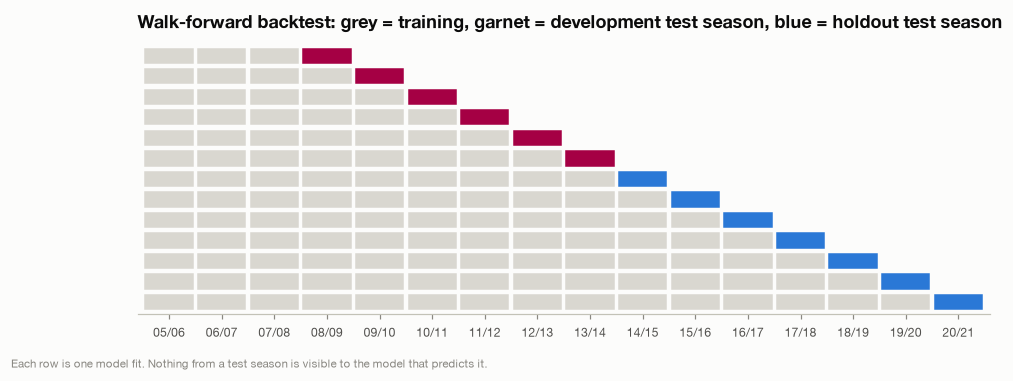

In [2]:
fig, ax = plt.subplots(figsize=(10, 3.2))
seasons = list(range(2005, 2021))
for i, test in enumerate(data.TEST_SEASONS):
    for s in seasons:
        if s < test:
            ax.add_patch(plt.Rectangle((s - 0.45, i - 0.35), 0.9, 0.7, color="#d9d7d0"))
        elif s == test:
            ax.add_patch(plt.Rectangle((s - 0.45, i - 0.35), 0.9, 0.7,
                                       color=style.BARCA if test in DEV else style.OPPONENT))
ax.set_xlim(2004.4, 2020.6)
ax.set_ylim(-0.6, len(data.TEST_SEASONS) - 0.4)
ax.set_xticks(seasons, [f"{s % 100:02d}/{(s + 1) % 100:02d}" for s in seasons], fontsize=8)
ax.set_yticks([])
ax.invert_yaxis()
ax.grid(False)
for s_ in ("left",):
    ax.spines[s_].set_visible(False)
ax.set_title("Walk-forward backtest: grey = training, garnet = development test season, blue = holdout test season")
style.caption(ax, "Each row is one model fit. Nothing from a test season is visible to the model that predicts it.")
style.savefig(fig, "12_walk_forward")
plt.show()

## Baseline 1: naive

Always predict the historical frequencies (about 47% home win, 25% draw,
28% away win). Any model worth using must beat this.

In [3]:
results = {}
dev_pred = {}
for name, make in [("naive", NaiveModel), ("elo", EloModel)]:
    pred, _ = backtest.walk_forward(ds, make, test_seasons=DEV)
    dev_pred[name] = pred
    results[name] = backtest.score(pred)
pl.DataFrame([{"model": k, **v} for k, v in results.items()])

model,n,log_loss,brier,rps,accuracy,macro_f1,ece
str,i64,f64,f64,f64,f64,f64,f64
"""naive""",2280,1.0422,0.6272,0.2253,0.4961,0.2210,0.0167
"""elo""",2280,0.9568,0.5670,0.1969,0.5544,0.3844,0.0215


## Baseline 2: Elo

An ordered logit of the result on the pre-match Elo difference. One
feature and two thresholds, and the home advantage is absorbed by the
thresholds. It is a large improvement on the naive baseline and, as the
rest of this notebook shows, very hard to beat.

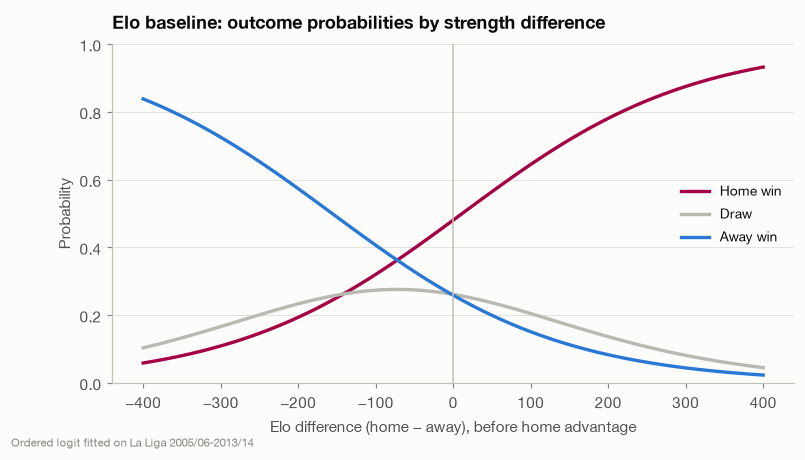

P(home, draw, away) for equal teams: [0.48  0.261 0.259]


In [4]:
elo = EloModel().fit(ds.rows(ds.season < 2014))
grid = np.linspace(-400, 400, 81)
import pandas as pd  # noqa: E402

pg = elo.predict_proba(pd.DataFrame({"elo_diff": grid}))
fig, ax = plt.subplots(figsize=(8, 4))
for k, (lab, col) in enumerate([("Home win", style.BARCA), ("Draw", style.NEUTRAL), ("Away win", style.OPPONENT)]):
    ax.plot(grid, pg[:, k], color=col, lw=2.2, label=lab)
ax.axvline(0, color=style.AXIS, lw=1)
ax.set_xlabel("Elo difference (home − away), before home advantage")
ax.set_ylabel("Probability")
ax.set_title("Elo baseline: outcome probabilities by strength difference")
ax.legend(loc="center right")
ax.set_ylim(0, 1)
style.caption(ax, "Ordered logit fitted on La Liga 2005/06-2013/14")
style.savefig(fig, "12_elo_baseline")
plt.show()
print("P(home, draw, away) for equal teams:", np.round(elo.predict_proba(pd.DataFrame({"elo_diff": [0.0]}))[0], 3))

Between equal teams the home side wins about 48% of the time and draws are
about 26% likely. Draws are most likely between evenly matched sides and
shrink as the gap grows.

## Baseline 3: multinomial logistic regression

Every one of the 90 features, standardised, with L2 regularisation. The
regularisation strength is the only choice, made on the development
seasons:

In [5]:
path = []
for C in (0.05, 0.01, 0.005, 0.002, 0.001, 0.0005):
    pred, _ = backtest.walk_forward(ds, lambda C=C: LogisticModel(C=C), test_seasons=DEV)
    path.append({"C": C, **backtest.score(pred)})
path = pl.DataFrame(path)
path.select("C", "log_loss", "rps", "ece")

C,log_loss,rps,ece
f64,f64,f64,f64
0.0500,0.9829,0.2013,0.0335
0.0100,0.9713,0.1993,0.0265
0.0050,0.9672,0.1987,0.0246
0.0020,0.9637,0.1983,0.0245
0.0010,0.9631,0.1985,0.0246
0.0005,0.9648,0.1992,0.0268


In [6]:
best_c = path.sort("log_loss")["C"][0]
pred, _ = backtest.walk_forward(ds, lambda: LogisticModel(C=best_c), test_seasons=DEV)
dev_pred["logistic"] = pred
results["logistic"] = backtest.score(pred)
print(f"chosen C = {best_c}")

chosen C = 0.001


With weak regularisation, 90 correlated features overfit and the model
loses to Elo alone. Strong regularisation (small C) recovers most of the
ground, but the logistic model still does not beat the single Elo feature.
The signal is concentrated in team strength, and extra features mostly add
variance (notebook 09's redundancy finding).

## Baseline 4: Poisson goals model

Instead of classifying the result, model the **goals**: expected goals for
each side,

$$ \lambda_{home} = e^{x\beta_h}, \qquad \lambda_{away} = e^{x\beta_a} $$

from pre-match strength and form features, then the full score
distribution. The classic refinement is the Dixon-Coles correction τ(x, y),
which re-weights the four low scores (0-0, 1-0, 0-1, 1-1) with one
parameter ρ, because independent Poissons are often said to under-predict
low-scoring draws. Both versions are tested.

In [7]:
dc_pred, fitted = backtest.walk_forward(ds, PoissonModel, test_seasons=DEV, keep_models=True)
print("Dixon-Coles rho by training window:", {s: round(m.rho_, 3) for s, m in fitted.items()})

Dixon-Coles rho by training window: {2008: -0.045, 2009: -0.021, 2010: -0.045, 2011: -0.038, 2012: -0.042, 2013: -0.034}


In [8]:
indep_pred, _ = backtest.walk_forward(ds, lambda: PoissonModel(dixon_coles=False), test_seasons=DEV)
dev_pred["poisson"] = indep_pred
results["poisson"] = backtest.score(indep_pred)
m13 = fitted[2013]
test13 = ds.rows(ds.season == 2013)
dc_m = m13.score_matrix(test13.X).mean(axis=0)
ind = PoissonModel(dixon_coles=False).fit(ds.rows(ds.season < 2013)).score_matrix(test13.X).mean(axis=0)
hg, ag = test13.goals()
obs = np.zeros_like(dc_m)
for h, a in zip(hg, ag, strict=True):
    obs[min(h, 10), min(a, 10)] += 1
obs /= obs.sum()
cells = [(0, 0), (1, 0), (0, 1), (1, 1), (2, 1), (2, 0), (0, 2), (2, 2)]
pl.DataFrame({
    "score": [f"{h}-{a}" for h, a in cells],
    "observed": [obs[h, a] for h, a in cells],
    "independent_poisson": [ind[h, a] for h, a in cells],
    "dixon_coles": [dc_m[h, a] for h, a in cells],
})

score,observed,independent_poisson,dixon_coles
str,f64,f64,f64
"""0-0""",0.0842,0.0735,0.0772
"""1-0""",0.1079,0.1042,0.1005
"""0-1""",0.0868,0.0810,0.0773
"""1-1""",0.0816,0.1094,0.1131
"""2-1""",0.0684,0.0797,0.0797
"""2-0""",0.0632,0.0799,0.0799
"""0-2""",0.0500,0.0490,0.0490
"""2-2""",0.0579,0.0425,0.0425


In [9]:
print("dev log loss, independent Poisson:", round(backtest.score(indep_pred)["log_loss"], 4),
      "| Dixon-Coles:", round(backtest.score(dc_pred)["log_loss"], 4))
print("observed draw rate 2013/14:", round(float((hg == ag).mean()), 3),
      "| predicted, independent:", round(float(np.trace(ind)), 3), "| Dixon-Coles:", round(float(np.trace(dc_m)), 3))

dev log loss, independent Poisson: 0.9578 | Dixon-Coles: 0.9582
observed draw rate 2013/14: 0.226 | predicted, independent: 0.234 | Dixon-Coles: 0.242


In this data the correction **does not help**. ρ is small and negative in
every training window. That lifts 0-0 (closer to what happened) but also
1-1, which independent Poissons already *over*-predict in La Liga here. The
net effect is a slightly worse log loss and a predicted draw rate further
from the observed one. The received wisdom does not transfer to this
league and period, so the simpler model is kept: **independent Poissons**
(D-026).

The goals model is on a par with Elo for the result, and it gives far more:
expected goals for each side and a full scoreline distribution, which the
app uses for "likely scores".

## Summary on the development seasons

In [10]:
summary = pl.DataFrame([{"model": k, **v} for k, v in results.items()]).sort("log_loss")
summary

model,n,log_loss,brier,rps,accuracy,macro_f1,ece
str,i64,f64,f64,f64,f64,f64,f64
"""elo""",2280,0.9568,0.5670,0.1969,0.5544,0.3844,0.0215
"""poisson""",2280,0.9578,0.5677,0.1975,0.5408,0.3777,0.0268
"""logistic""",2280,0.9631,0.5705,0.1985,0.5553,0.3873,0.0246
"""naive""",2280,1.0422,0.6272,0.2253,0.4961,0.2210,0.0167


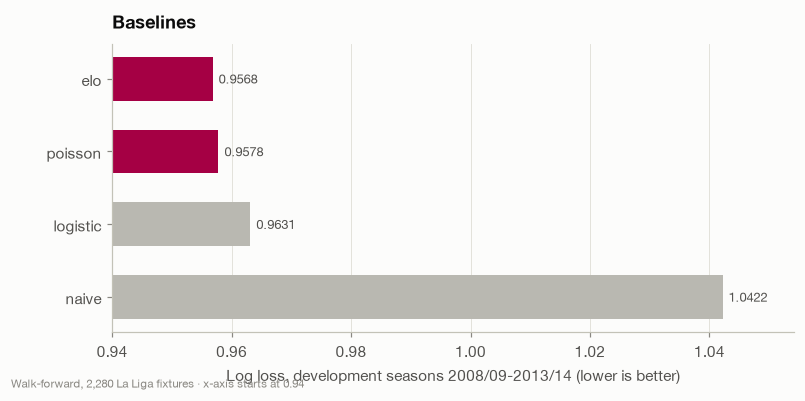

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.4))
s = summary.sort("log_loss", descending=True)
ax.barh(s["model"], s["log_loss"], color=[style.BARCA if m in ("elo", "poisson") else style.NEUTRAL for m in s["model"]],
        height=0.6)
for y_, v in enumerate(s["log_loss"]):
    ax.text(v + 0.001, y_, f"{v:.4f}", va="center", fontsize=8.5, color=style.INK_2)
ax.set_xlim(0.94, max(s["log_loss"]) + 0.012)
ax.set_xlabel("Log loss, development seasons 2008/09-2013/14 (lower is better)")
ax.set_title("Baselines")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
style.caption(ax, "Walk-forward, 2,280 La Liga fixtures · x-axis starts at 0.94")
style.savefig(fig, "12_baselines")
plt.show()

## Findings

1. **Elo is the baseline to beat.** One well-built feature takes most of
   the available signal.
2. **More features are not automatically better**: the 90-feature logistic
   model needs heavy regularisation and still trails Elo.
3. **The Poisson goals model matches Elo** on the result and adds a score
   distribution, so it is kept as the score model. The Dixon-Coles
   correction was tested and rejected: it made predictions slightly worse
   here.

Next: tree ensembles, tuning, experiment tracking and the question of
whether event data helps (`13_ml_models`).